In [1]:
import numpy as np
import matplotlib.pyplot as plt

We set `seed=42` throughout this task.

In [2]:
rng = np.random.default_rng(seed=42)

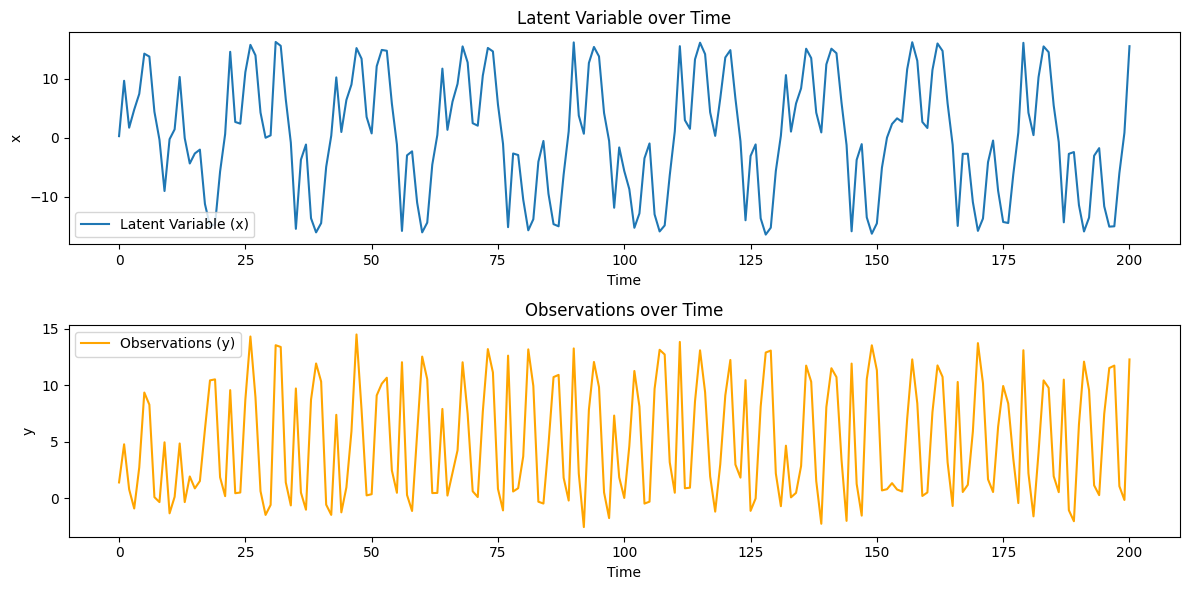

In [3]:
# Latent variable
def latent_variable(t):
    x = np.empty(t + 1)
    x[0] = rng.normal(loc=0.0, scale=1.0)
    for i in range(1, t + 1):
        x[i] = 0.5 * x[i - 1] + 25 * x[i - 1] / (1 + x[i - 1] ** 2) + 8 * np.cos(1.2 * i) + rng.normal(loc=0.0, scale=np.sqrt(0.1))
    return x

# Observations
def observations(x):
    y = x ** 2 / 20 + rng.normal(loc=0.0, scale=np.sqrt(1.0), size=x.shape)
    return y

# Generate data
t = 200
x = latent_variable(t)
y = observations(x)

# Plotting
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(x, label='Latent Variable (x)')
plt.title('Latent Variable over Time')
plt.xlabel('Time')
plt.ylabel('x')
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(y, label='Observations (y)', color='orange')
plt.title('Observations over Time')
plt.xlabel('Time')
plt.ylabel('y')
plt.legend()
plt.tight_layout()
plt.show()

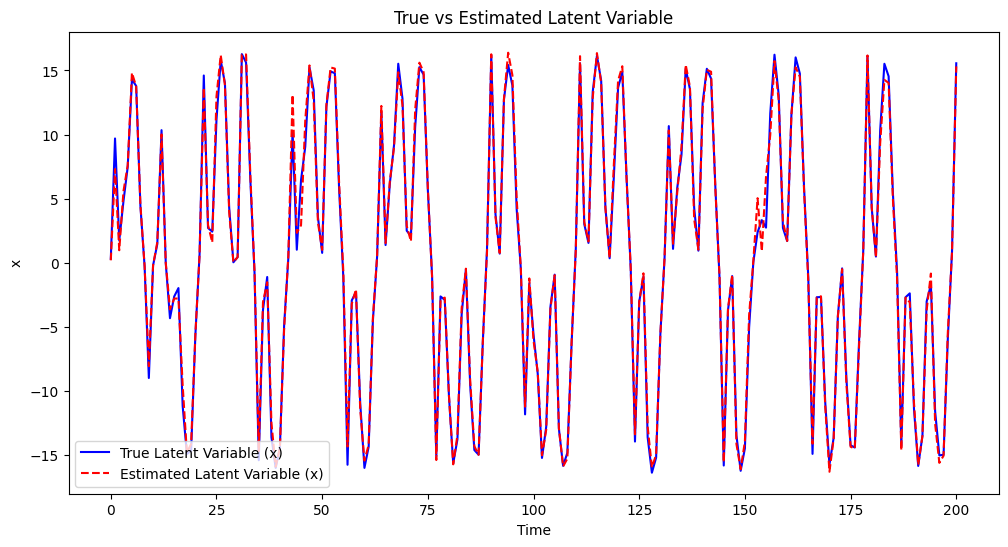

In [4]:
# for simple calculation, we use bootstrap proposal
def weight(x, y):
    return np.exp(-0.5 * (y - x ** 2 / 20) ** 2)/np.sqrt(2 * np.pi)

def particle_filter(y, num):
    particles = np.empty((num, len(y)))
    weights = np.empty((num, len(y)))
    
    # Initialize particles
    particles[:, 0] = rng.normal(loc=0.0, scale=1.0, size=num)
    weights[:, 0] = weight(particles[:, 0], y[0])/np.sum(weight(particles[:, 0], y[0]))
    
    for t in range(1, len(y)):
        particles[:, t] = 0.5 * particles[:, t - 1] + 25 * particles[:, t - 1] / (1 + particles[:, t - 1] ** 2) + 8 * np.cos(1.2 * t) + rng.normal(loc=0.0, scale=np.sqrt(0.1), size=num)
        weights[:, t] = weight(particles[:, t], y[t])
        weights[:, t] = weights[:, t - 1] * weights[:, t]
        weights[:, t] /= np.sum(weights[:, t]) # Normalize weights

        # Resample particles
        indices = rng.choice(num, size=num, replace=True, p=weights[:, t])
        particles[:, t] = particles[indices, t]
        weights[: ,t] = np.ones(num) / num  # Reset weights after resampling
    
    return particles, weights

def particle_filter_paths(y, num):
    T = len(y)
    particles = np.empty((num, T))  
    weights = np.empty((num, T))

    particles[:, 0] = rng.normal(loc=0.0, scale=1.0, size=num)
    w = weight(particles[:, 0], y[0])
    w = w / np.sum(w)
    weights[:, 0] = w

    indices = rng.choice(num, size=num, replace=True, p=w)
    particles[:, 0] = particles[indices, 0]
    weights[:, 0] = np.ones(num) / num

    for t in range(1, T):
        particles[:, t] = (
            0.5 * particles[:, t - 1]
            + 25 * particles[:, t - 1] / (1 + particles[:, t - 1] ** 2)
            + 8 * np.cos(1.2 * t)
            + rng.normal(loc=0.0, scale=np.sqrt(0.1), size=num)
        )

        w = weight(particles[:, t], y[t])
        w = w / np.sum(w)
        weights[:, t] = w

        indices = rng.choice(num, size=num, replace=True, p=w)
        particles[:, :t+1] = particles[indices, :t+1]

        weights[:, t] = np.ones(num) / num

    return particles, weights

def ffbsa(y, num):

    # Take the marginal samples at each time step
    length_y = len(y)
    x_smoothed = np.empty(length_y)
    p, w = particle_filter(y, num)
    x_smoothed[-1] = rng.choice(p[:, -1], p=w[:, -1])
    # Backward sampling
    for n in range(length_y - 1, 0, -1):
        prob = w[:, n-1] * np.exp(-0.5 * (x_smoothed[n] - 0.5 * p[:, n-1] - 25 * p[:, n-1] / (1 + p[:, n-1] ** 2) - 8 * np.cos(1.2 * (n))) ** 2 / 0.1)
        prob /= np.sum(prob)
        x_smoothed[n-1] = rng.choice(p[:, n-1], p=prob)

    return x_smoothed

num_particles = 500
estimated_x = ffbsa(y, num_particles)
# Plotting the results
plt.figure(figsize=(12, 6))
plt.plot(x, label='True Latent Variable (x)', color='blue')
plt.plot(estimated_x, label='Estimated Latent Variable (x)', color='red', linestyle='dashed')
plt.title('True vs Estimated Latent Variable')
plt.xlabel('Time')
plt.ylabel('x')
plt.legend()
plt.show()

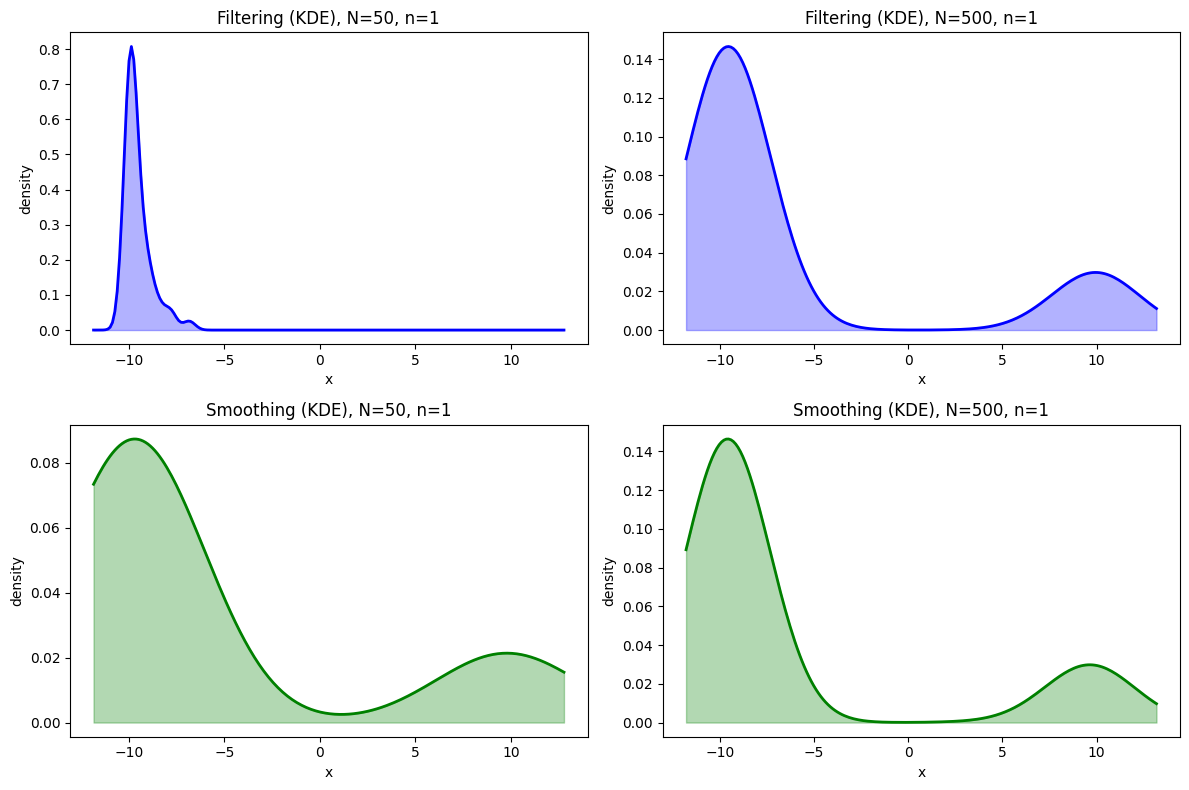

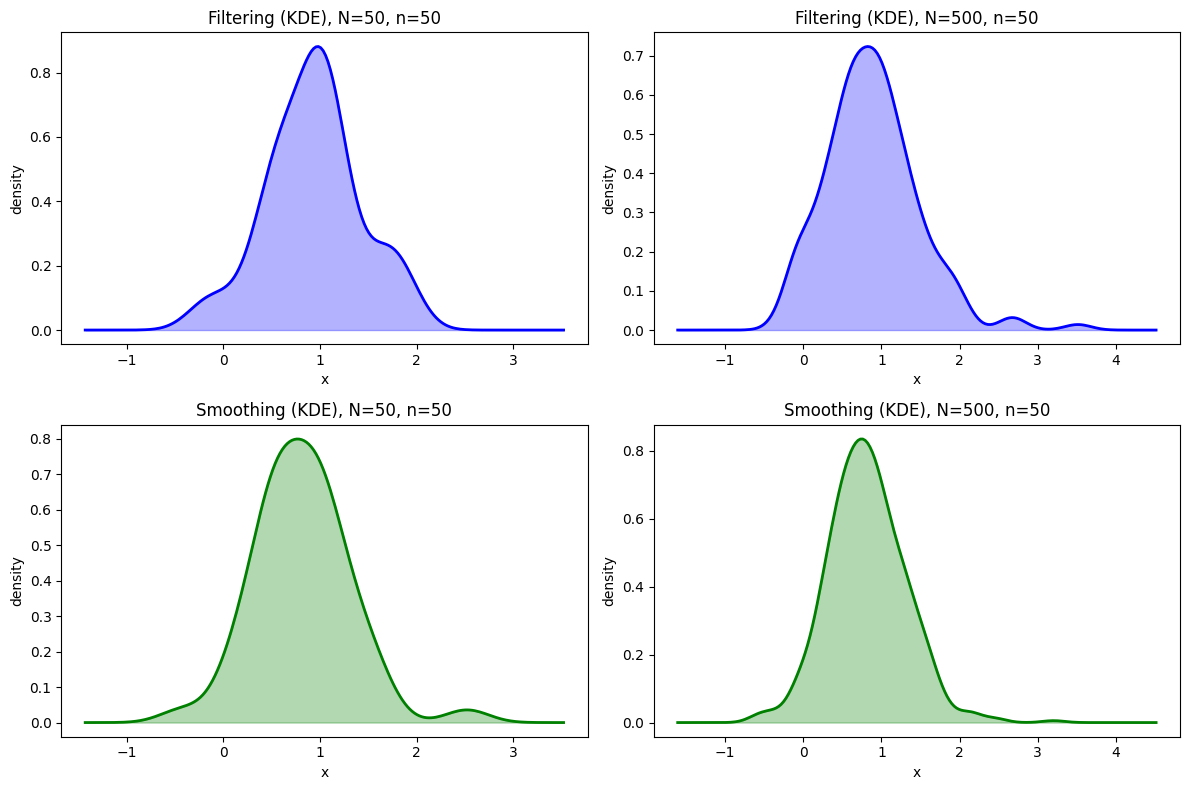

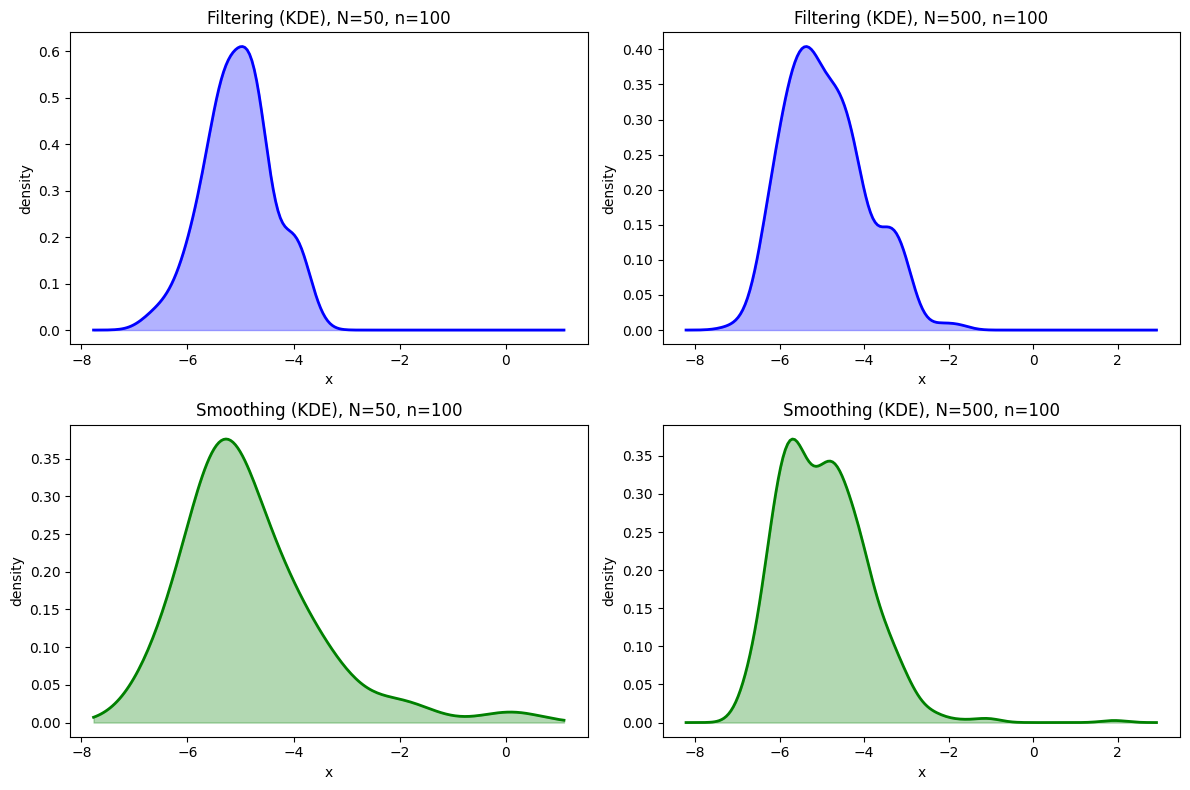

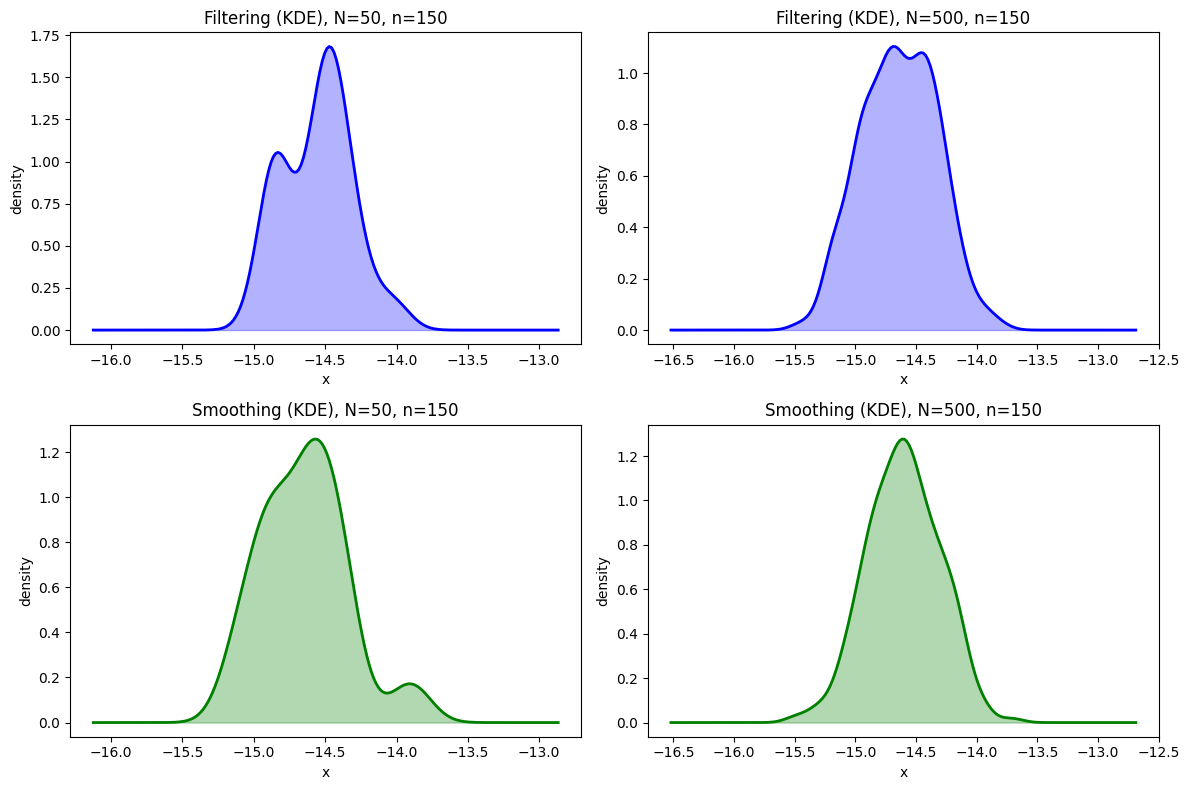

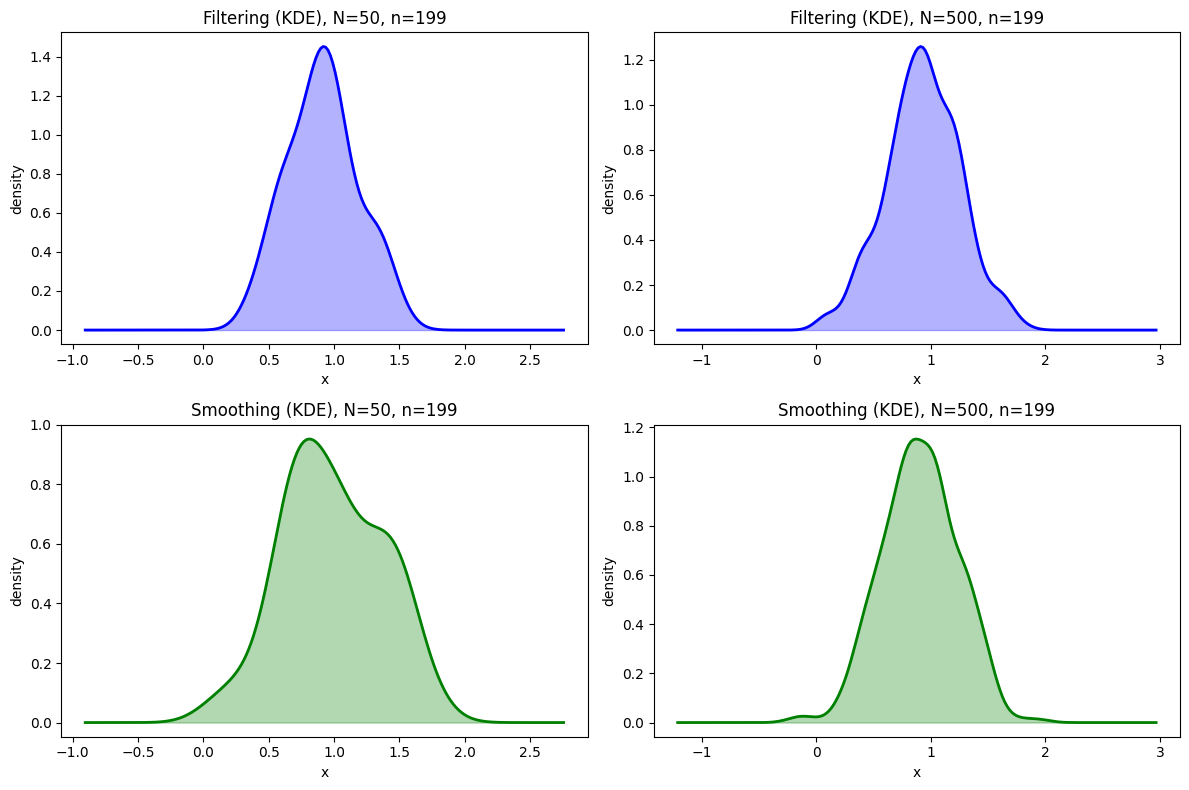

In [5]:
import os
from scipy.stats import gaussian_kde

time_steps = [1, 50, 100, 150, 199]
N_simulations = [50, 500]

def plot_filter_density_cases(y_data, n_values=time_steps, N_values=N_simulations):
    os.makedirs("question_1", exist_ok=True)

    for n in n_values:
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        
        for col, N in enumerate(N_values):
            p_forward, w_forward = particle_filter(y_data[:n+1], num=N)
            x_f = p_forward[:, -1]
            weights_f = w_forward[:, -1]

            x_s = []
            for _ in range(N):
                path = ffbsa(y_data[:n+1], N)
                x_s.append(path[n])
            x_s = np.array(x_s)

            x_grid = np.linspace(min(x_f.min(), x_s.min()) - 1, 
                                 max(x_f.max(), x_s.max()) + 1, 200)

            kde_f = gaussian_kde(x_f, weights=weights_f)
            axes[0, col].plot(x_grid, kde_f(x_grid), color='blue', lw=2)
            axes[0, col].fill_between(x_grid, kde_f(x_grid), alpha=0.3, color='blue')
            axes[0, col].set_title(f"Filtering (KDE), N={N}, n={n}")
            
            kde_s = gaussian_kde(x_s)
            axes[1, col].plot(x_grid, kde_s(x_grid), color='green', lw=2)
            axes[1, col].fill_between(x_grid, kde_s(x_grid), alpha=0.3, color='green')
            axes[1, col].set_title(f"Smoothing (KDE), N={N}, n={n}")

        for ax in axes.flat:
            ax.set_xlabel("x")
            ax.set_ylabel("density")
        
        plt.tight_layout()
        filename = f"./question_1/pf_kde_step_{n}.png"
        plt.savefig(filename, dpi=300)
        plt.show()
        plt.close(fig)

plot_filter_density_cases(y)

Comments：
- Accuracy: To assess the accuracy of the particle approximations, we compare the filtering and smoothing distributions for a fixed $N$. At each time step $n$, the similarity in the support and modal structure of the density estimates suggests that the algorithms are consistent and the results are reliable. Furthermore, as expected in Monte Carlo methods, increasing the number of particles from $N=50$ to $N=500$ significantly reduces the approximation error and produces more stable posterior estimates.

- Justification of the term "Smoother": Regarding the terminology, the answer is YES, the term "smoother" is well-justified here. While a larger $N$ improves the precision of the density estimation, the primary distinction lies in the variance of the distribution: the smoothing density $p(x_n | y_{0:T})$  consistently exhibits a "smoother" and more concentrated profile compared to the filtering density $p(x_n | y_{0:n})$. This is because the smoothing algorithm (FFBSa) incorporates "future" observations relative to time $n$, thereby reducing the posterior uncertainty and providing a more refined estimate of the latent state.

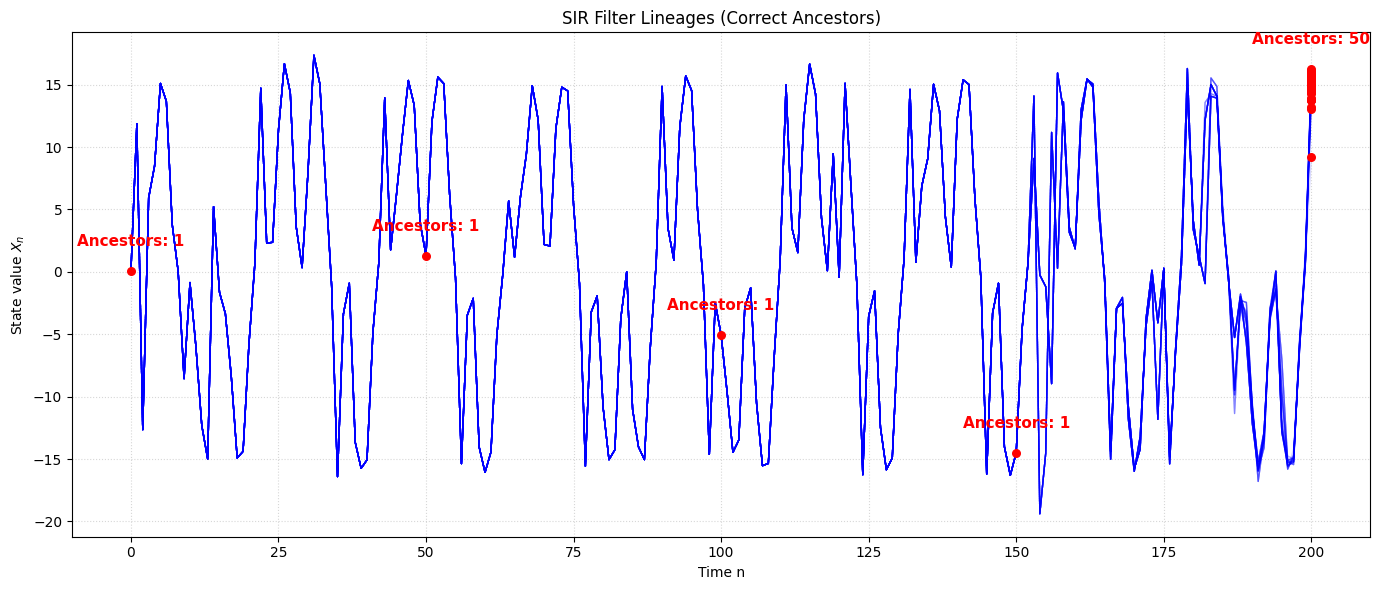

In [12]:
import numpy as np
import matplotlib.pyplot as plt

N = 50

# ============================================================
# Particle filter + ancestry tracking
# ============================================================

def pf_ancestry_with_indices(y, N):
    T = len(y)

    particles_pre = np.empty((N, T))
    ancestors = np.empty((N, T), dtype=int)

    # initial
    p = np.random.normal(0, 1, size=N)
    w = np.exp(-0.5 * (y[0] - p**2 / 20)**2)
    w = w / np.sum(w)

    idx = np.random.choice(N, size=N, p=w)

    particles_pre[:, 0] = p
    ancestors[:, 0] = np.arange(N)
    current_resampled = p[idx]

    for t in range(1, T):
        p_gen = (
            0.5 * current_resampled
            + 25 * current_resampled / (1 + current_resampled**2)
            + 8 * np.cos(1.2 * t)
            + np.random.normal(0, np.sqrt(0.1), size=N)
        )

        particles_pre[:, t] = p_gen

        w = np.exp(-0.5 * (y[t] - p_gen**2 / 20)**2)
        w = w / np.sum(w)

        idx = np.random.choice(N, size=N, p=w)

        ancestors[:, t] = idx
        current_resampled = p_gen[idx]

    # reconstruct lineage
    paths = np.empty((N, T))
    index_paths = np.empty((N, T), dtype=int)

    for i in range(N):
        curr_idx = i
        paths[i, -1] = particles_pre[curr_idx, -1]
        index_paths[i, -1] = curr_idx

        for t in range(T - 2, -1, -1):
            curr_idx = ancestors[curr_idx, t + 1]
            paths[i, t] = particles_pre[curr_idx, t]
            index_paths[i, t] = curr_idx

    return paths, index_paths


# ============================================================
# Lineage plot（正确的 ancestor nodes）
# ============================================================

def plot_reconstructed_lineage(paths, index_paths, title, color):
    N_paths, T_len = paths.shape

    plt.figure(figsize=(14, 6))

    # trajectories
    for i in range(N_paths):
        plt.plot(paths[i, :], color=color, alpha=0.15, lw=1)

    check_pts = [0, 50, 100, 150, 200]

    for pt in check_pts:
        unique_indices = np.unique(index_paths[:, pt])
        n_unique = len(unique_indices)

        # 对应这些 ancestor 的 state 值
        values = paths[unique_indices, pt]

        plt.scatter([pt] * n_unique, values, color='red', s=30, zorder=5)

        plt.text(
            pt,
            np.max(values) + 2,
            f'Ancestors: {n_unique}',
            color='red',
            fontweight='bold',
            ha='center',
            fontsize=11
        )

    plt.title(title)
    plt.xlabel('Time n')
    plt.ylabel(r'State value $X_n$')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()


# ============================================================
# Run
# ============================================================

paths, index_paths = pf_ancestry_with_indices(y, N)

plot_reconstructed_lineage(
    paths,
    index_paths,
    title="SIR Filter Lineages (Correct Ancestors)",
    color="blue"
)

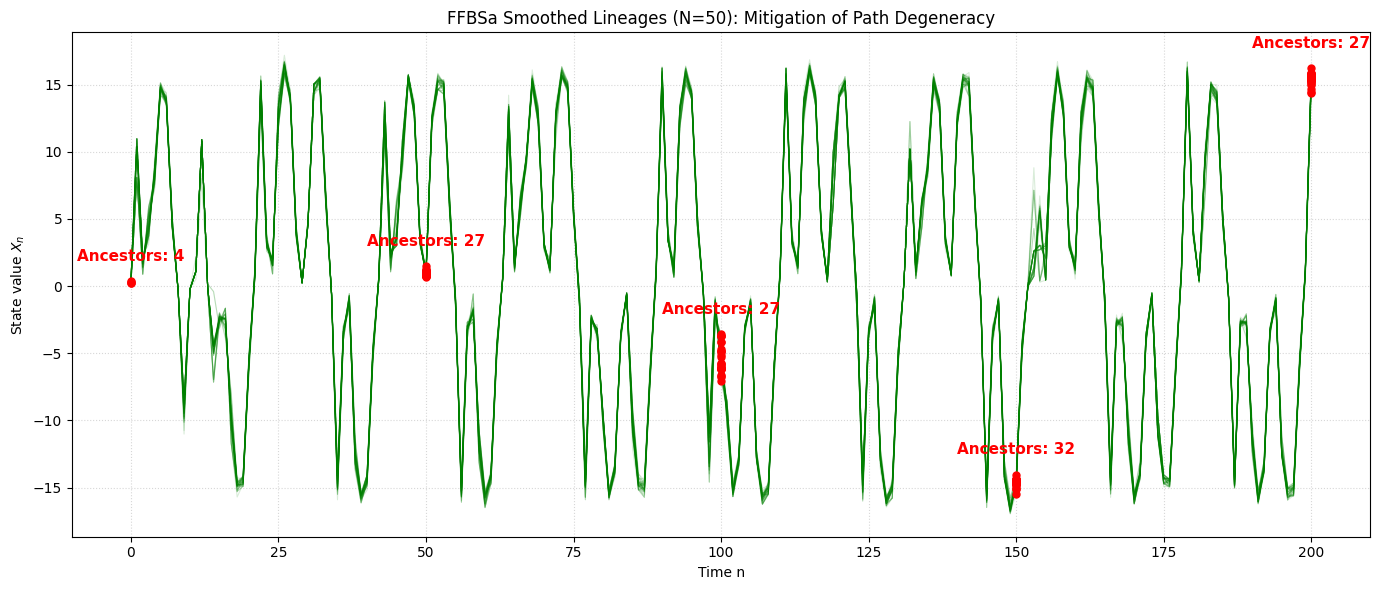

In [11]:
p, w = particle_filter(y, N)
T_len = p.shape[1]

def ffbsa_lineages_with_indices(p_filter, w_filter, num_paths=50):
    """
    FFBSa backward trajectories, storing both state values and particle indices.

    Returns
    -------
    smoothed_paths : array, shape (num_paths, T_len)
        Sampled state values.

    smoothed_indices : array, shape (num_paths, T_len)
        Particle indices selected at each time.
    """
    N, T_len = p_filter.shape

    smoothed_paths = np.empty((num_paths, T_len))
    smoothed_indices = np.empty((num_paths, T_len), dtype=int)

    for m in range(num_paths):
        # sample terminal index
        idx_T = rng.choice(N, p=w_filter[:, -1])
        smoothed_indices[m, -1] = idx_T
        smoothed_paths[m, -1] = p_filter[idx_T, -1]

        for n in range(T_len - 1, 0, -1):
            x_next = smoothed_paths[m, n]

            x_prev_particles = p_filter[:, n-1]

            f_x = (
                0.5 * x_prev_particles
                + 25 * x_prev_particles / (1 + x_prev_particles**2)
                + 8 * np.cos(1.2 * n)
            )

            log_prob_trans = -0.5 * (x_next - f_x)**2 / 0.1

            log_weights = np.log(w_filter[:, n-1] + 1e-300) + log_prob_trans
            log_weights -= np.max(log_weights)

            prob = np.exp(log_weights)
            prob /= np.sum(prob)

            idx_prev = rng.choice(N, p=prob)

            smoothed_indices[m, n-1] = idx_prev
            smoothed_paths[m, n-1] = p_filter[idx_prev, n-1]

    return smoothed_paths, smoothed_indices

smoothed_paths, smoothed_indices = ffbsa_lineages_with_indices(p, w, num_paths=N)

plt.figure(figsize=(14, 6))

for i in range(N):
    plt.plot(smoothed_paths[i, :], color='green', alpha=0.15, linewidth=0.8)

check_pts = [0, 50, 100, 150, 200]

for pt in check_pts:
    unique_indices = np.unique(smoothed_indices[:, pt])
    num_unique = len(unique_indices)

    unique_values = p[unique_indices, pt]

    plt.scatter(
        [pt] * num_unique,
        unique_values,
        color='red',
        s=25,
        zorder=5
    )

    plt.text(
        pt,
        np.max(unique_values) + 1.5,
        f'Ancestors: {num_unique}',
        color='red',
        fontweight='bold',
        ha='center',
        fontsize=11
    )

plt.title(f'FFBSa Smoothed Lineages (N={N}): Mitigation of Path Degeneracy')
plt.xlabel('Time n')
plt.ylabel(r'State value $X_n$')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

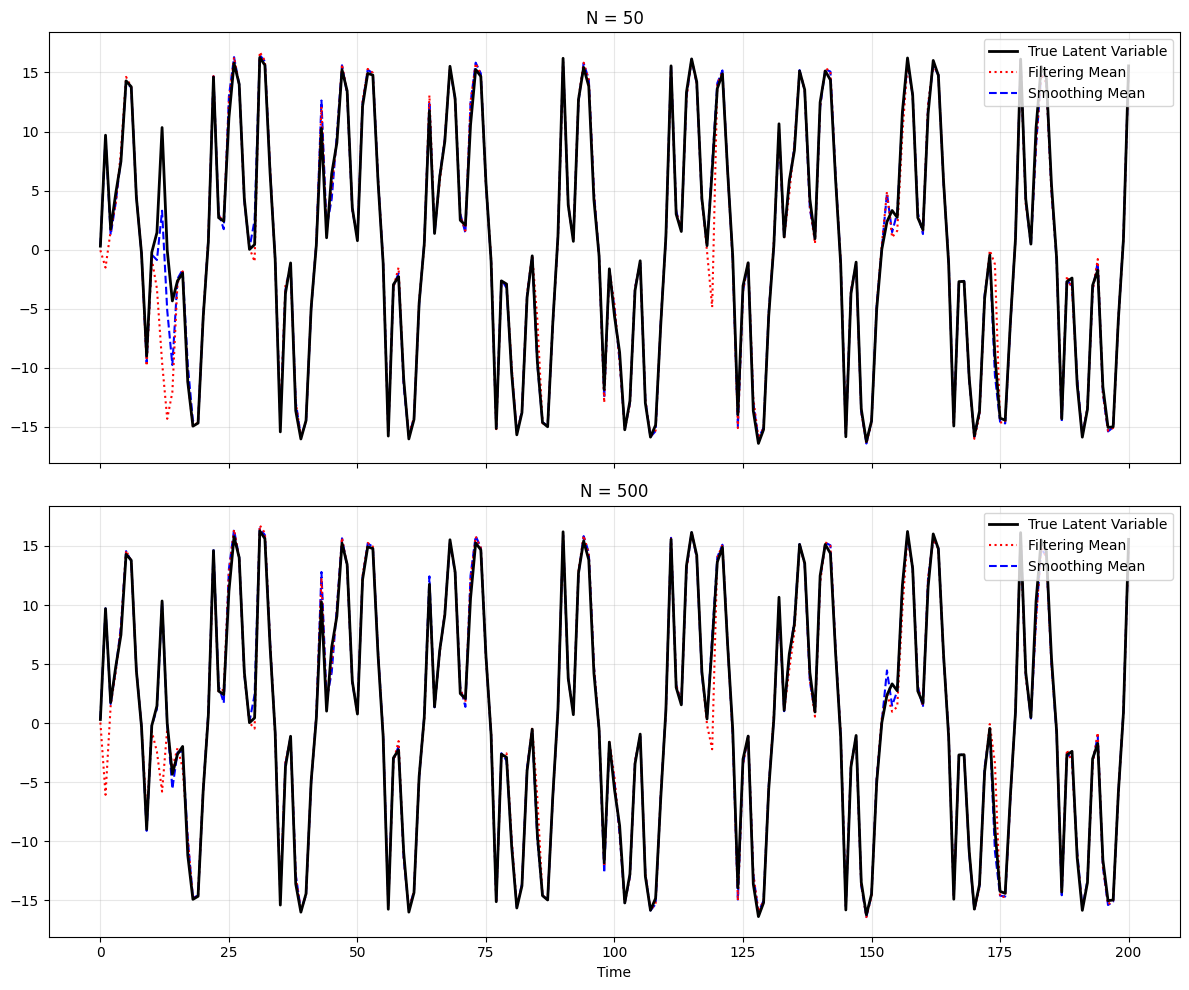

In [8]:
def filter_mean(y, num):
    length_y = len(y)
    x_mean = np.empty(length_y)
    p, w = particle_filter(y, num)
    for n in range(length_y):
        x_mean[n] = np.sum(p[:, n] * w[:, n])
    return x_mean

def ffbsa_mean(y, num, M):
    particles = np.empty((M, len(y)))
    for t in range(M):
        x_smoothed = ffbsa(y, num)
        particles[t, :] = x_smoothed
    return np.mean(particles, axis=0)

num_particles = [50, 500]
M = 100  # Number of samples for mean estimation
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for i, num in enumerate(num_particles):
    smoothed_x_mean = ffbsa_mean(y, num, M)
    filter_x_mean = filter_mean(y, num)

    axes[i].plot(x, label='True Latent Variable', color='black', linewidth=2, zorder=4)

    axes[i].plot(filter_x_mean, label='Filtering Mean', color='red', 
                 linestyle=':', linewidth=1.5, zorder=3)
    
    axes[i].plot(smoothed_x_mean, label='Smoothing Mean', color='blue', 
                 linestyle='--', linewidth=1.5, zorder=2)
    
    axes[i].set_title(f'N = {num}')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.3)

axes[1].set_xlabel('Time')
plt.tight_layout()
plt.show()



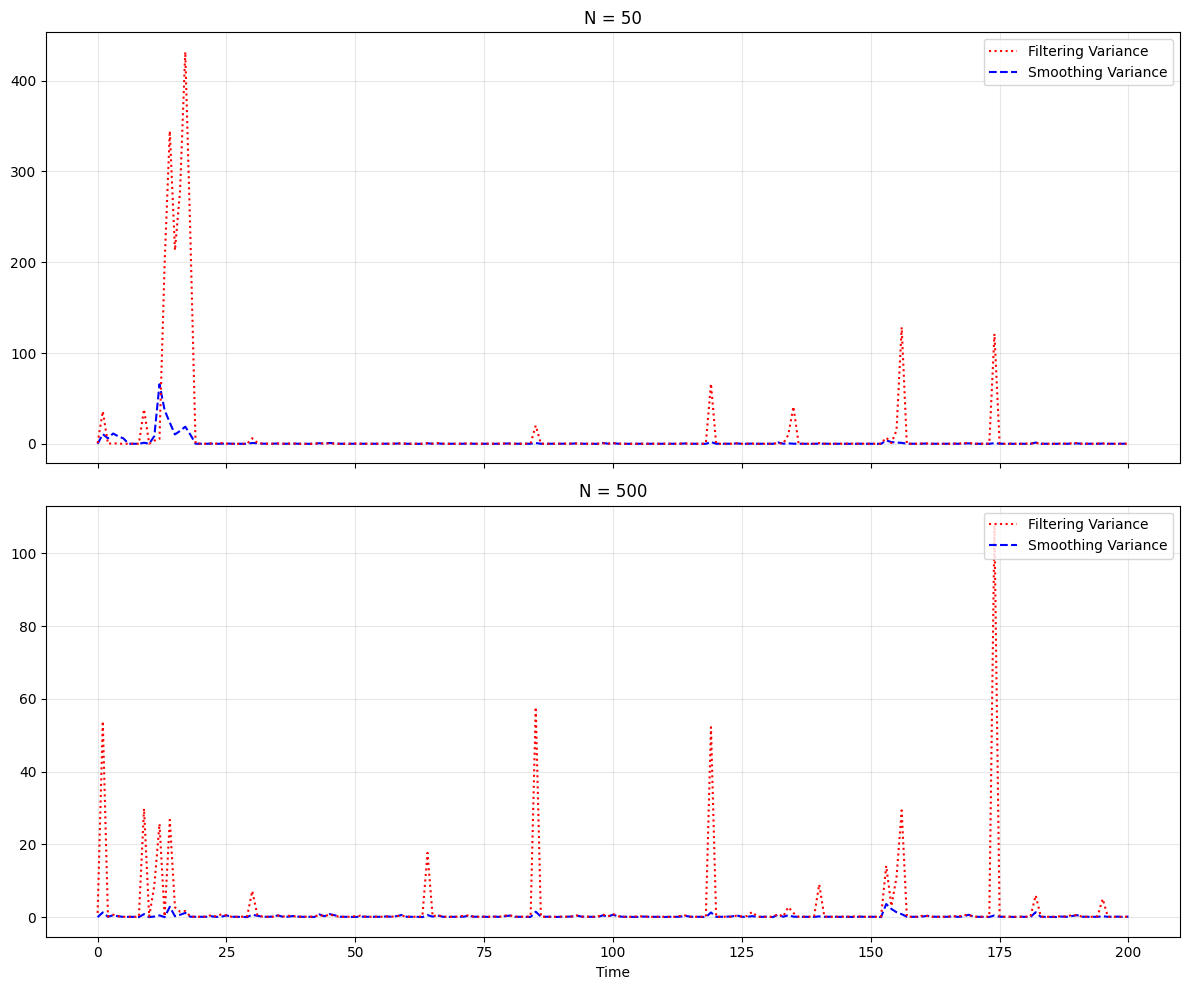

In [9]:
def filter_var(y, num):
    length_y = len(y)
    filter_mean_values = filter_mean(y, num)
    x_var = np.empty(length_y)
    p, w = particle_filter(y, num)
    for n in range(length_y):
        x_var[n] = np.sum((p[:, n] - filter_mean_values[n]) ** 2 * w[:, n])
    return x_var

def ffbsa_var(y, num, M=100):
    length_y = len(y)
    particles = np.empty((M, length_y))
    for t in range(M):
        x_smoothed = ffbsa(y, num)
        particles[t, :] = x_smoothed

    return np.var(particles, axis=0)

num_particles = [50, 500]
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for i, num in enumerate(num_particles):
    smoothed_x_var = ffbsa_var(y, num)
    filter_x_var = filter_var(y, num)

    axes[i].plot(filter_x_var, label='Filtering Variance', color='red', 
                 linestyle=':', linewidth=1.5, zorder=3)
    
    axes[i].plot(smoothed_x_var, label='Smoothing Variance', color='blue', 
                 linestyle='--', linewidth=1.5, zorder=2)
    
    axes[i].set_title(f'N = {num}')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.3)

axes[1].set_xlabel('Time')
plt.tight_layout()
plt.show()



For this nonlinear state-space model with $T=200$, both Particle Filtering (PF) and Forward Filtering Backward Sampling (FFBSa) are able to capture the general evolution of the latent state, but FFBSa provides a more accurate overall reconstruction, with its posterior mean tracking the true state trajectory more closely. The standard PF is more affected by Monte Carlo variability and path degeneracy, which can lead to less stable local behaviour and occasionally inaccurate short-term trends, whereas FFBSa alleviates these issues by incorporating future observations through a backward-sampling step, making it more reliable for estimating past states. This advantage is also reflected in the density and variance plots: compared with PF, FFBSa produces smoother posterior densities and generally smaller posterior variances over most time points, indicating lower estimation uncertainty, while the two methods coincide at $t=T$ as expected. However, this improvement comes at a higher computational cost, since PF has complexity $O(TN)$, whereas FFBSa scales as $O(TN^2)$, so the running time increases much more rapidly as the number of particles grows from $N=50$ to $N=500$. The benefit of smoothing is particularly clear in this model because the state dynamics are highly nonlinear, due to the $\frac{25x}{1+x^2}$ term and the oscillatory forcing term $8\cos(1.2n)$, while the observation equation $\frac{x^2}{20}$ introduces sign ambiguity, since positive and negative states may generate similar observations. These features make posterior inference more challenging for a forward-only particle method, whereas FFBSa, by using the full observation sequence, is better able to reduce ambiguity and improve the reconstruction of the hidden states.

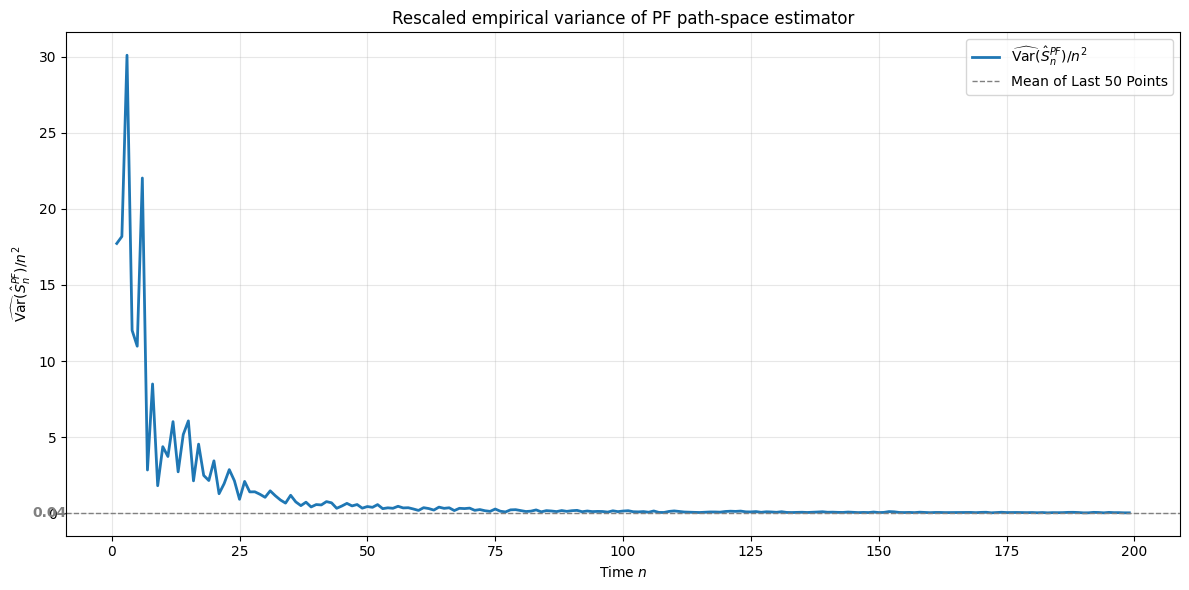

In [18]:
def stheta_pf_runs(y, num_particles, n, num_runs=50):
    """
    Return num_runs independent PF estimates of
        S_n = E[ sum_{k=0}^n X_k | y_{0:n} ]
    using the PF path-space estimator.
    """
    psi_list = np.empty(num_runs)

    for r in range(num_runs):
        particles, weights = particle_filter_paths(y, num_particles)

        # Full paths truncated at time n
        x_path = particles[:, :n+1]
        w_n = weights[:, n]

        path_sums = np.sum(x_path, axis=1)
        psi_hat = np.sum(path_sums * w_n)

        psi_list[r] = psi_hat

    return psi_list


def empirical_variance_pf(y, num_particles, n, num_runs=50):
    """
    Empirical variance across num_runs independent PF runs.
    """
    estimates = stheta_pf_runs(y, num_particles, n, num_runs=num_runs)
    return np.var(estimates, ddof=1)


# -----------------------------
# Plot rescaled empirical variance
# -----------------------------
n_max = 200
num_particles = 50
num_runs = 50

time_points = np.arange(1, n_max)
var_list = np.empty(len(time_points))

for idx, n in enumerate(time_points):
    var_estimate = empirical_variance_pf(y, num_particles, n, num_runs=num_runs)
    var_list[idx] = var_estimate / (n ** 2)

plt.figure(figsize=(12, 6))
plt.plot(time_points, var_list, linewidth=2,
         label=r'$\widehat{\mathrm{Var}}(\hat S_n^{PF})/n^2$')
plt.axhline(np.mean(var_list[150:201]), color='gray', linestyle='--', linewidth=1, label='Mean of Last 50 Points')
plt.text(0, np.mean(var_list[150:201]), f'{np.mean(var_list[150:201]):.2f}', color='gray', 
         transform=plt.gca().get_yaxis_transform(), 
         ha='right', va='center', fontweight='bold')
plt.title(r'Rescaled empirical variance of PF path-space estimator')
plt.xlabel('Time $n$')
plt.ylabel(r'$\widehat{\mathrm{Var}}(\hat S_n^{PF})/n^2$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

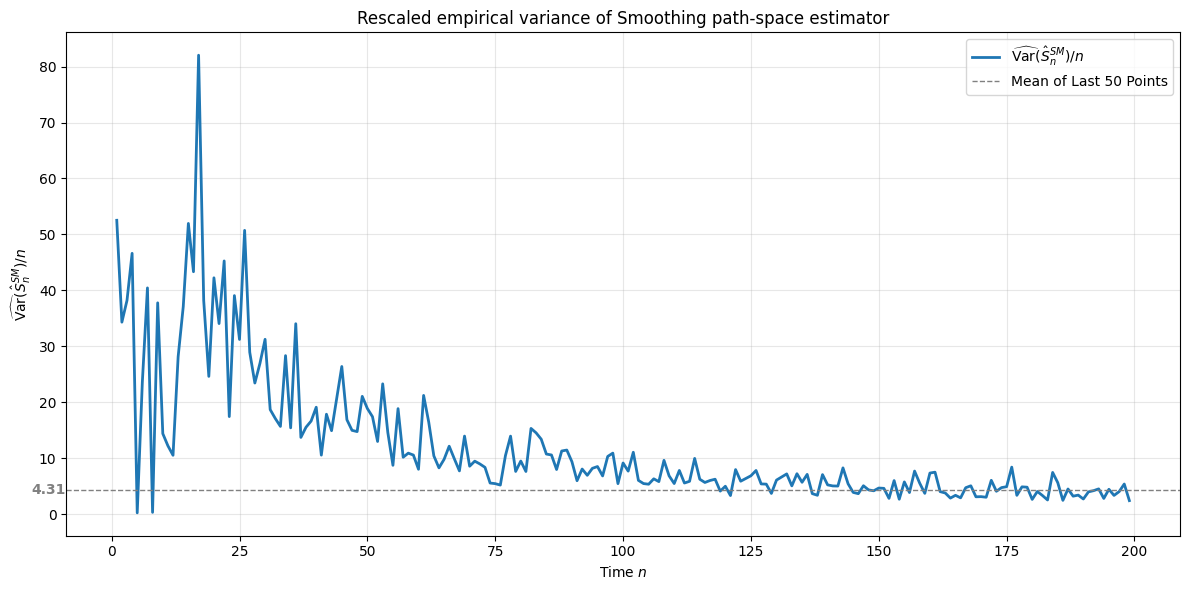

In [19]:
def stheta_ffbsa_runs(y, num_particles, n, num_runs=50):
    """
    Return num_runs independent FFBSa estimates of
        S_n = E[ sum_{k=0}^n X_k | y_{0:n} ]
    using the FFBSa path-space estimator.
    """
    psi_list = np.empty(num_runs)

    for r in range(num_runs):
        smoothed_path = ffbsa(y[:n+1], num_particles)
        psi_hat = np.sum(smoothed_path[:n+1])
        psi_list[r] = psi_hat

    return psi_list

def empirical_variance_ffbsa(y, num_particles, n, num_runs=50):
    estimates = stheta_ffbsa_runs(y, num_particles, n)
    return np.var(estimates)

var_list = np.empty(len(time_points))
for idx, n in enumerate(time_points):
    var_estimate = empirical_variance_ffbsa(y, num_particles, n)
    var_list[idx] = var_estimate / (n)

plt.figure(figsize=(12, 6))
plt.plot(time_points, var_list, linewidth=2,
         label=r'$\widehat{\mathrm{Var}}(\hat S_n^{SM})/n$')
plt.axhline(np.mean(var_list[150:201]), color='gray', linestyle='--', linewidth=1, label='Mean of Last 50 Points')
plt.text(0, np.mean(var_list[150:201]), f'{np.mean(var_list[150:201]):.2f}', color='gray', 
         transform=plt.gca().get_yaxis_transform(), 
         ha='right', va='center', fontweight='bold')
plt.title(r'Rescaled empirical variance of Smoothing path-space estimator')
plt.xlabel('Time $n$')
plt.ylabel(r'$\widehat{\mathrm{Var}}(\hat S_n^{SM})/n$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

